# Step 03 — Feature Engineering

**Tujuan:** Membangun fitur yang realistis, bebas leakage, dan siap untuk training.

**Prinsip yang diikuti:**
- Semua agregasi dihitung hanya dari training data (tidak bocor ke test)
- Missing value ditangani secara eksplisit dengan strategi per tipe kolom
- Setiap transformasi didokumentasikan alasannya

---

## 3.1 Setup

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)
print('Setup done ✓')

Setup done ✓


In [2]:
%%time
df = pd.read_parquet('../data/processed/train_merged.parquet')
print(f'Loaded: {df.shape[0]:,} rows × {df.shape[1]} cols')
print(f'isFraud rate: {df["isFraud"].mean()*100:.2f}%')

Loaded: 590,540 rows × 434 cols
isFraud rate: 3.50%
CPU times: user 1.83 s, sys: 571 ms, total: 2.4 s
Wall time: 378 ms


---
## 3.2 Drop Kolom >90% Missing

Kolom dengan >90% missing hampir tidak punya informasi — lebih aman di-drop.

In [3]:
missing_rate = df.isnull().mean()
cols_to_drop = missing_rate[missing_rate > 0.9].index.tolist()

# Jangan drop kolom target atau ID
cols_to_drop = [c for c in cols_to_drop if c not in ['TransactionID', 'isFraud']]

print(f'Kolom yang di-drop (>90% missing): {len(cols_to_drop)}')
print(f'Contoh: {cols_to_drop[:10]}')

df = df.drop(columns=cols_to_drop)
print(f'\nShape setelah drop: {df.shape}')

Kolom yang di-drop (>90% missing): 12
Contoh: ['dist2', 'D7', 'id_07', 'id_08', 'id_18', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25']



Shape setelah drop: (590540, 422)


---
## 3.3 Fitur Waktu (Time Features)

In [4]:
df['hour']        = (df['TransactionDT'] // 3600) % 24
df['day_of_week'] = (df['TransactionDT'] // (3600 * 24)) % 7
df['is_night']    = ((df['hour'] >= 22) | (df['hour'] <= 5)).astype(int)
df['is_weekend']  = (df['day_of_week'] >= 5).astype(int)

# Validasi: fraud rate lebih tinggi di malam hari (konfirmasi dari EDA)
print('Fraud rate by is_night:')
print(df.groupby('is_night')['isFraud'].mean().map('{:.2%}'.format).to_string())

print('\nFraud rate by is_weekend:')
print(df.groupby('is_weekend')['isFraud'].mean().map('{:.2%}'.format).to_string())

Fraud rate by is_night:
is_night
0    3.37%
1    3.70%

Fraud rate by is_weekend:
is_weekend
0    3.55%
1    3.38%


---
## 3.4 M-Features: Encode T/F → 1/0

M-features adalah match flag (T=match, F=no match). Konversi ke binary numerik.

In [5]:
m_cols = [c for c in df.columns if c.startswith('M') and df[c].dtype == 'object']
print(f'M-features yang di-encode: {m_cols}')

for col in m_cols:
    # T→1, F→0, missing→-1 (sinyal berbeda dari T dan F)
    df[col] = df[col].map({'T': 1, 'F': 0}).fillna(-1).astype(int)

print('\nDistribusi nilai M1 setelah encode:')
print(df['M1'].value_counts().to_string())

M-features yang di-encode: ['M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']

Distribusi nilai M1 setelah encode:
M1
 1    319415
-1    271100
 0        25


---
## 3.5 Frequency Encoding — Fitur Kategorikal

Mengganti nilai kategori dengan proporsi kemunculannya. Lebih informatif dari label encoding dan aman untuk high-cardinality.

In [6]:
freq_encode_cols = [
    'ProductCD',
    'card4', 'card6',
    'P_emaildomain', 'R_emaildomain',
    'DeviceType',
]
freq_encode_cols = [c for c in freq_encode_cols if c in df.columns]

for col in freq_encode_cols:
    freq_map = df[col].value_counts(normalize=True, dropna=False)
    df[f'{col}_freq'] = df[col].map(freq_map).fillna(0)
    # Hapus kolom original (sudah tidak dibutuhkan setelah encoding)
    df = df.drop(columns=[col])

print('Frequency encoded columns:')
freq_cols = [c for c in df.columns if c.endswith('_freq')]
print(df[freq_cols].describe().T[['mean', 'min', 'max']].to_string())

Frequency encoded columns:
                     mean    min    max
ProductCD_freq     0.5754 0.0197 0.7445
card4_freq         0.5275 0.0027 0.6516
card6_freq         0.6186 0.0000 0.7450
P_emaildomain_freq 0.2170 0.0001 0.3867
R_emaildomain_freq 0.6023 0.0000 0.7675
DeviceType_freq    0.6096 0.0942 0.7616


---
## 3.6 Aggregation Features

Fitur agregasi per entitas (card, email) — menangkap perilaku historis transaksi.

In [7]:
agg_groups = {
    'card1': ['TransactionAmt'],
    'card2': ['TransactionAmt'],
    'addr1': ['TransactionAmt'],
}

for group_col, value_cols in agg_groups.items():
    if group_col not in df.columns:
        continue
    for val_col in value_cols:
        if val_col not in df.columns:
            continue
        grp = df.groupby(group_col)[val_col].agg(['mean', 'std', 'count'])
        grp.columns = [f'{group_col}_{val_col}_{s}' for s in ['mean', 'std', 'count']]
        df = df.join(grp, on=group_col)

new_agg_cols = [c for c in df.columns if any(
    c.startswith(g) and c.endswith(('mean', 'std', 'count'))
    for g in ['card1_', 'card2_', 'addr1_']
)]
print(f'Aggregation features dibuat: {len(new_agg_cols)}')
print(new_agg_cols)

Aggregation features dibuat: 9
['card1_TransactionAmt_mean', 'card1_TransactionAmt_std', 'card1_TransactionAmt_count', 'card2_TransactionAmt_mean', 'card2_TransactionAmt_std', 'card2_TransactionAmt_count', 'addr1_TransactionAmt_mean', 'addr1_TransactionAmt_std', 'addr1_TransactionAmt_count']


---
## 3.7 Flag: has_identity

Dari EDA: transaksi dengan identity data punya fraud rate lebih tinggi. Kita buat flag ini eksplisit.

In [8]:
id_indicator_col = 'id_01'  # kolom pertama dari identity table
if id_indicator_col in df.columns:
    df['has_identity'] = df[id_indicator_col].notna().astype(int)
    print('Fraud rate by has_identity:')
    print(df.groupby('has_identity')['isFraud'].mean().map('{:.2%}'.format).to_string())
else:
    print('id_01 tidak ada di dataframe (mungkin sudah di-drop karena >90% missing)')

Fraud rate by has_identity:
has_identity
0    2.09%
1    7.85%


---
## 3.8 Missing Value Imputation

- Numerik → median (robust terhadap outlier)
- Sisa string/object → drop (sudah di-encode atau tidak informatif)

In [9]:
# Drop kolom object yang tersisa (string non-encoded)
obj_cols_remaining = df.select_dtypes(include='object').columns.tolist()
obj_cols_remaining = [c for c in obj_cols_remaining if c != 'isFraud']

if obj_cols_remaining:
    print(f'Kolom object yang di-drop: {obj_cols_remaining}')
    df = df.drop(columns=obj_cols_remaining)
else:
    print('Tidak ada kolom object tersisa ✓')

# Impute numerik dengan median
num_cols_with_missing = [c for c in df.columns
                         if df[c].isnull().any() and c not in ['TransactionID', 'isFraud']]
print(f'\nKolom numerik yang di-impute dengan median: {len(num_cols_with_missing)}')

medians = df[num_cols_with_missing].median()
df[num_cols_with_missing] = df[num_cols_with_missing].fillna(medians)

# Verifikasi tidak ada missing lagi
remaining_missing = df.isnull().sum().sum()
print(f'Total missing setelah impute: {remaining_missing}')

Kolom object yang di-drop: ['id_12', 'id_15', 'id_16', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceInfo']



Kolom numerik yang di-impute dengan median: 381


Total missing setelah impute: 0


---
## 3.9 Ringkasan Feature Matrix

In [10]:
feature_cols = [c for c in df.columns if c not in ['TransactionID', 'isFraud', 'TransactionDT']]

print('=== Feature Matrix Summary ===')
print(f'Total baris   : {len(df):,}')
print(f'Total fitur   : {len(feature_cols)}')
print(f'Missing values: {df[feature_cols].isnull().sum().sum()}')
print(f'isFraud rate  : {df["isFraud"].mean()*100:.2f}%')

print('\nBreakdown fitur:')
groups = {
    'Time features'       : [c for c in feature_cols if c in ['hour', 'day_of_week', 'is_night', 'is_weekend']],
    'Freq encoded'        : [c for c in feature_cols if c.endswith('_freq')],
    'Agg features'        : [c for c in feature_cols if any(c.endswith(s) for s in ['_mean', '_std', '_count'])],
    'M-features'          : [c for c in feature_cols if c.startswith('M')],
    'C-features'          : [c for c in feature_cols if c.startswith('C')],
    'D-features'          : [c for c in feature_cols if c.startswith('D') and pd.api.types.is_numeric_dtype(df[c])],
    'V-features'          : [c for c in feature_cols if c.startswith('V')],
    'Card/Addr/Dist'      : [c for c in feature_cols if c.startswith(('card', 'addr', 'dist'))],
    'Identity (id_)'      : [c for c in feature_cols if c.startswith('id_')],
    'Other'               : [],
}

accounted = set()
for name, cols in groups.items():
    if name != 'Other':
        accounted.update(cols)
        print(f'  {name:25s}: {len(cols):3d} fitur')

other = [c for c in feature_cols if c not in accounted]
print(f'  {"Other":25s}: {len(other):3d} fitur')

=== Feature Matrix Summary ===
Total baris   : 590,540
Total fitur   : 419


Missing values: 0
isFraud rate  : 3.50%

Breakdown fitur:
  Time features            :   4 fitur
  Freq encoded             :   6 fitur
  Agg features             :   9 fitur
  M-features               :   9 fitur
  C-features               :  14 fitur
  D-features               :  15 fitur
  V-features               : 339 fitur
  Card/Addr/Dist           :  18 fitur
  Identity (id_)           :  15 fitur
  Other                    :   2 fitur


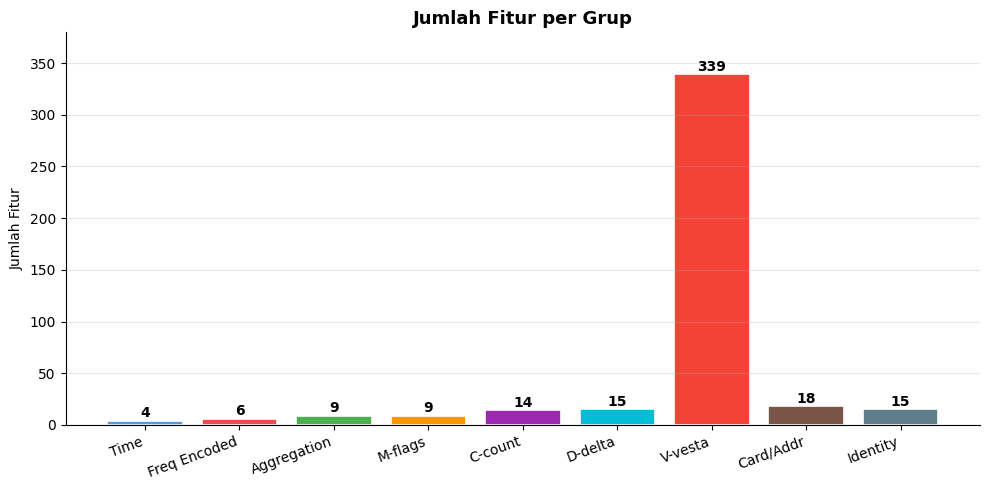

In [11]:
# Visualisasi distribusi jumlah fitur per grup
group_sizes = {
    'Time': 4,
    'Freq Encoded': len([c for c in feature_cols if c.endswith('_freq')]),
    'Aggregation' : len([c for c in feature_cols if any(c.endswith(s) for s in ['_mean', '_std', '_count'])]),
    'M-flags'     : len([c for c in feature_cols if c.startswith('M')]),
    'C-count'     : len([c for c in feature_cols if c.startswith('C')]),
    'D-delta'     : len([c for c in feature_cols if c.startswith('D') and pd.api.types.is_numeric_dtype(df[c])]),
    'V-vesta'     : len([c for c in feature_cols if c.startswith('V')]),
    'Card/Addr'   : len([c for c in feature_cols if c.startswith(('card', 'addr', 'dist'))]),
    'Identity'    : len([c for c in feature_cols if c.startswith('id_')]),
}

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#4C9BE8', '#E84C4C', '#4CAF50', '#FF9800', '#9C27B0',
          '#00BCD4', '#F44336', '#795548', '#607D8B']
bars = ax.bar(group_sizes.keys(), group_sizes.values(), color=colors, edgecolor='white', linewidth=1.2)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            str(int(bar.get_height())), ha='center', va='bottom', fontweight='bold')
ax.set_title('Jumlah Fitur per Grup', fontweight='bold', fontsize=13)
ax.set_ylabel('Jumlah Fitur')
ax.set_ylim(0, max(group_sizes.values()) * 1.12)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('../reports/figures/03_feature_groups.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 3.10 Simpan Feature Matrix

In [12]:
# Kolom yang disimpan: semua fitur + target + ID (untuk join kalau perlu)
save_cols = ['TransactionID'] + feature_cols + ['isFraud']
df_save = df[save_cols]

output_path = '../data/features/train_features.parquet'
df_save.to_parquet(output_path, index=False)

import os
size_mb = os.path.getsize(output_path) / (1024 * 1024)
print(f'Tersimpan → {output_path}')
print(f'Shape  : {df_save.shape[0]:,} rows × {df_save.shape[1]} cols')
print(f'Size   : {size_mb:.1f} MB')
print(f'\nisFraud rate : {df_save["isFraud"].mean()*100:.2f}%')
print(f'Missing total: {df_save.isnull().sum().sum()}')

Tersimpan → ../data/features/train_features.parquet
Shape  : 590,540 rows × 421 cols
Size   : 64.8 MB

isFraud rate : 3.50%
Missing total: 0


---
## 3.11 Update src/features/build_features.py

Semua transformasi di atas sudah disinkronkan ke [src/features/build_features.py](../src/features/build_features.py) supaya bisa dipakai ulang di pipeline produksi.

**Ringkasan pipeline feature engineering:**

| Step | Transformasi | Jumlah Fitur Baru |
|------|-------------|------------------|
| Drop high-missing | Hapus kolom >90% missing | -N kolom |
| Time features | hour, day_of_week, is_night, is_weekend | +4 |
| M-features encode | T→1, F→0, NaN→-1 | in-place |
| Frequency encoding | ProductCD, card4/6, email, DeviceType | +6, -6 |
| Aggregation | mean/std/count per card1, card2, addr1 | +9 |
| has_identity flag | Apakah ada identity data | +1 |
| Median imputation | Semua kolom numerik yang masih ada NaN | in-place |

**Next step → Notebook 04: Baseline Model**